## 1. Ingesta y Validación Estructural
- **Acción:** Cargar el .parquet y ejecutar una inspección
- **A verificar:** número exacto de registro y columnas. Validar el peso en memoria (RAM) del df.
- **Salida esperada:** Una  lista clara separando las variables por tipo inferido.

#### Importación de librerías y config inicial

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

#config visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#Opcioones de pandas para poder visualizar todas las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

#### Definición de la estructura de directorios

In [2]:
BASE_DIR = '../'
DATA_DIR = os.path.join(BASE_DIR, 'data')

RAW_DIR = os.path.join(DATA_DIR, 'raw')
SAMPLE_DIR = os.path.join(DATA_DIR, 'sample')
PROCESSED_DIR = os.path.join(DATA_DIR, 'processed')

#crear los directorios en caso de que no existan
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(SAMPLE_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
print("Estructura de directorios creada correctamente.")

Estructura de directorios creada correctamente.


#### Ingesta del CSV, conversión a .parquet y generación del archivo de muestra (data/sample/)

In [ ]:
#Rutas de los archivos
csv_path = os.path.join(RAW_DIR, 'LC_loans_granting_model_dataset.csv')
parquet_path = os.path.join(RAW_DIR, 'LC_loans_granting_model_dataset.parquet')
sample_path = os.path.join(SAMPLE_DIR, 'sample_dataset.csv')

if not os.path.exists(parquet_path):
    print ("Leyendo e archivo CSV")
    # Cargar el CSV
    df_raw = pd.read_csv(csv_path, low_memory=False)

    # Guardar como .parquet
    print("Convirtiendo y guardando en parquet")
    df_raw.to_parquet(parquet_path, engine='pyarrow', index=False)

    print("Generando muestra aleatorio de 1000 filas para testing")
    df_sample = df_raw.sample(n=1000, random_state=42)
    df_sample.to_csv(sample_path, index=False)

    print(f"Archivo .parquet creado en: {parquet_path}")
    print(f"Archivo de muestra creado en: {sample_path}")

    print("Proceso finalizado. Memoria liberada")
    del df_raw, df_sample
else:
    print(f"El archivo .parquet ya existe en: {parquet_path}")

El archivo .parquet ya existe en: ../data\raw\LC_loans_granting_model_dataset.parquet


#### Lectura optimizada e inspección estructural

In [5]:
# Ingesta desde el formato columnar Parquet
df = pd.read_parquet(parquet_path)

# 1. Inspección estructural
print(f"Cantidad de filas: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")
print(f"Uso de memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB\n")

# Extraer tipos de datos y separarlos
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
datetime_cols = df.select_dtypes(include=['datetime64']).columns.tolist()

print(f"Variables numéricas ({len(num_cols)}): {num_cols}")
print(f"Variables categóricas/textuales ({len(cat_cols)}): {cat_cols}")
if datetime_cols:
    print(f"Variables de fecha ({len(datetime_cols)}): {datetime_cols}")

# Vista preliminar
display(df.head())

Cantidad de filas: 1,347,681
Cantidad de columnas: 15
Uso de memoria: 718.75 MB

Variables numéricas (7): ['id', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'Default']
Variables categóricas/textuales (8): ['issue_d', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'title', 'desc']


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0000,5.9100,3600,677.0000,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,None
1,68355089,Dec-2015,65000.0000,16.0600,24700,717.0000,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,None
2,68341763,Dec-2015,71000.0000,13.8500,20000,697.0000,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,None,None
3,68476807,Dec-2015,104433.0000,25.3700,10400,697.0000,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,None
4,68426831,Dec-2015,34000.0000,10.2000,11950,692.0000,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,None


#### Diagnóstico de la variable objetivo (Default)

,Cantidad,Porcentaje (%)
Default,,
0,1078432,80.0213
1,269249,19.9787


C:\Users\Equipo\AppData\Local\Temp\ipykernel_5256\3049200162.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=target_summary.index, y=target_summary['Porcentaje (%)'], palette='viridis')


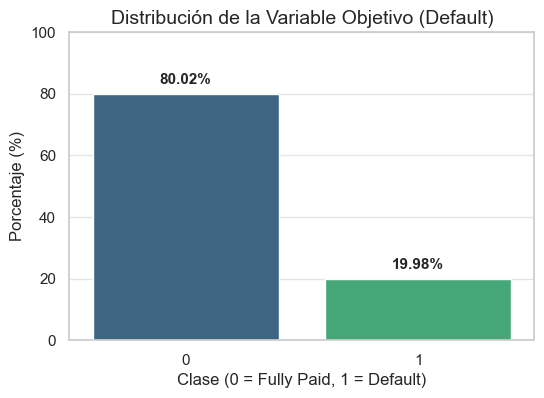

In [6]:
# Frecuencias absolutas
target_counts = df['Default'].value_counts()
# Frecuencias relativas (porcentajes)
target_pct = df['Default'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Cantidad': target_counts,
    'Porcentaje (%)': target_pct
})

display(target_summary)

# Visualización del desequilibrio
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=target_summary.index, y=target_summary['Porcentaje (%)'], palette='viridis')
plt.title('Distribución de la Variable Objetivo (Default)', fontsize=14)
plt.xlabel('Clase (0 = Fully Paid, 1 = Default)', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)

# Añadir etiquetas con los porcentajes exactos sobre las barras
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.ylim(0, 100)
plt.show()

#### Mapeo de Valores Nulos

,Nulos,Porcentaje (%)
desc,1228582,91.1627
title,16657,1.2360
zip_code,1,0.0001


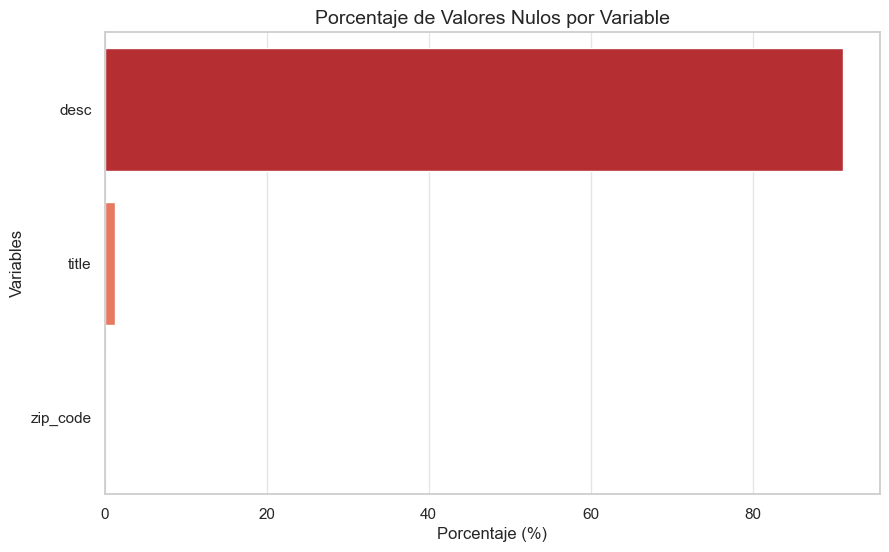

In [7]:
missing_data = df.isnull().sum()
missing_pct = (missing_data / len(df)) * 100

# Filtramos solo las que tienen nulos y las ordenamos
missing_df = pd.DataFrame({'Nulos': missing_data, 'Porcentaje (%)': missing_pct})
missing_df = missing_df[missing_df['Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False)

display(missing_df)

if not missing_df.empty:
    plt.figure(figsize=(10, 6))
    # Aplicamos el fix de Seaborn (hue y legend=False) para evitar el FutureWarning
    sns.barplot(
        x=missing_df['Porcentaje (%)'],
        y=missing_df.index,
        hue=missing_df.index,
        palette='Reds_r',
        legend=False
    )
    plt.title('Porcentaje de Valores Nulos por Variable', fontsize=14)
    plt.xlabel('Porcentaje (%)')
    plt.ylabel('Variables')
    plt.show()
else:
    print("¡Excelente! No hay valores nulos en el dataset.")

#### Análisis Univariado Numérico
- Separaremos las variables continuas y analizaremos su distribución (omitiendo el id y nuestro target Default que ya estudiamos).

,revenue,dti_n,loan_amnt,fico_n,experience_c
count,1347681.0000,1347681.0000,1347681.0000,1347681.0000,1347681.0000
mean,77369.6832,18.2991,14408.2305,698.1589,1.0000
std,70362.9896,11.1521,8715.3474,31.8487,0.0043
min,1896.0000,0.0000,500.0000,612.0000,0.0000
25%,46600.0000,11.8200,7975.0000,672.0000,1.0000
50%,65000.0000,17.6300,12000.0000,692.0000,1.0000
75%,92000.0000,24.0700,20000.0000,712.0000,1.0000
max,10999200.0000,999.0000,40000.0000,847.5000,1.0000


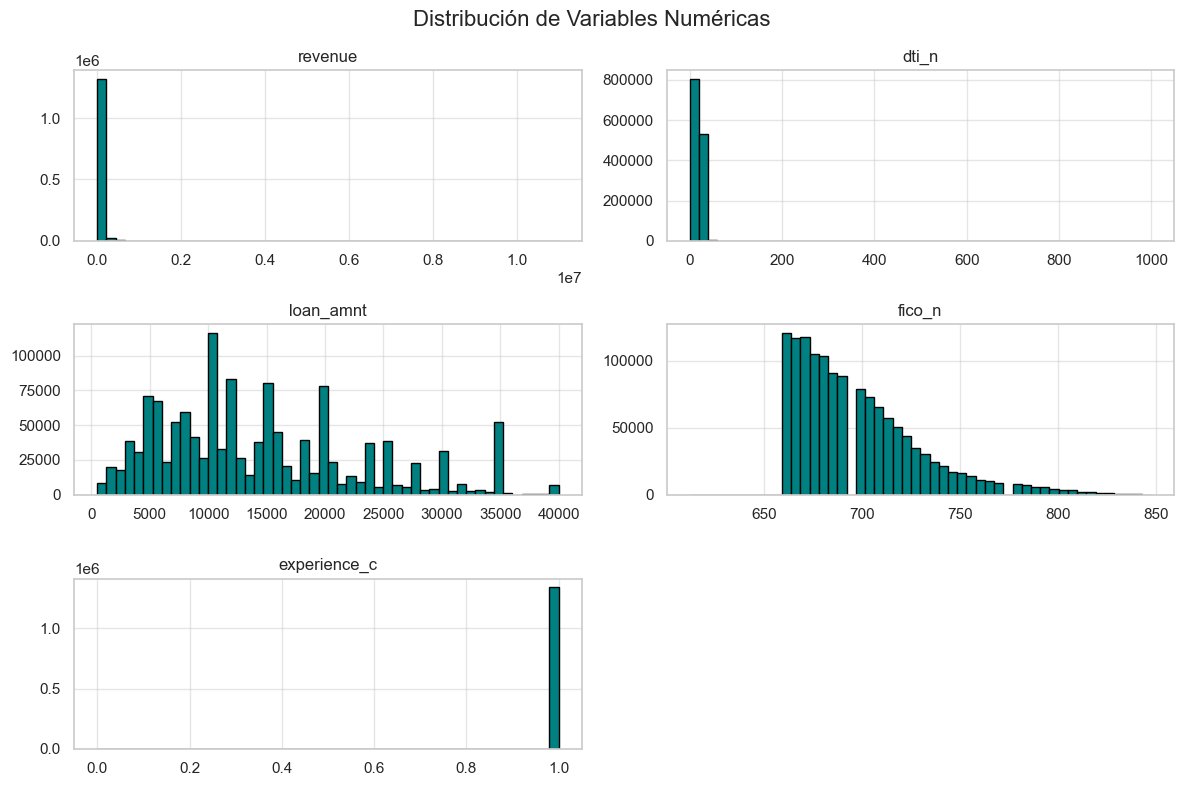

In [8]:
# Excluimos 'id' y 'Default' para el análisis estadístico
features_num = [col for col in num_cols if col not in ['id', 'Default']]

# Tabla de estadística descriptiva (media, min, max, cuartiles)
display(df[features_num].describe())

# Visualización mediante histogramas
df[features_num].hist(bins=50, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle('Distribución de Variables Numéricas', fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
df['experience_c'].value_counts()

experience_c
1    1347656
0         25
Name: count, dtype: int64

#### Cardinalidad de Variables Categóricas
- Analizaremos cuántos valores únicos tiene cada variable categórica (omitiendo los textos puros title y desc). Esto es crucial para saber si podemos aplicar One-Hot Encoding o si la variable tiene tanta dispersión (como los códigos postales) que rompería nuestro modelo tabular

,Variable,Valores Únicos
5,zip_code,945
0,issue_d,139
4,addr_state,51
2,purpose,14
1,emp_length,12
3,home_ownership_n,4


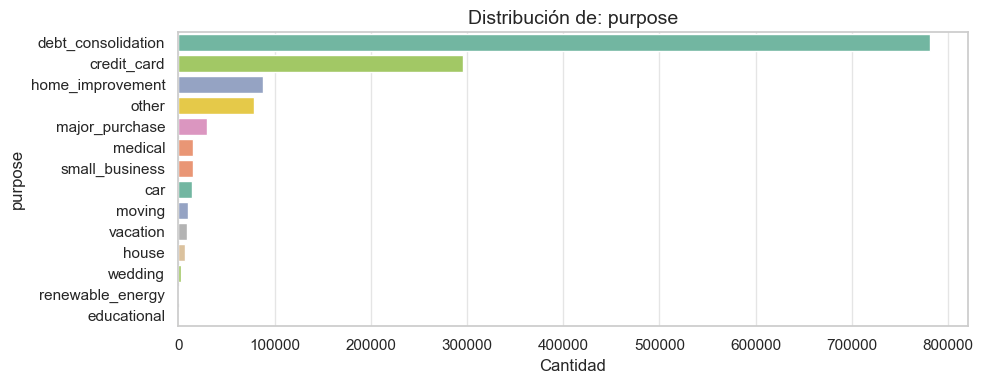

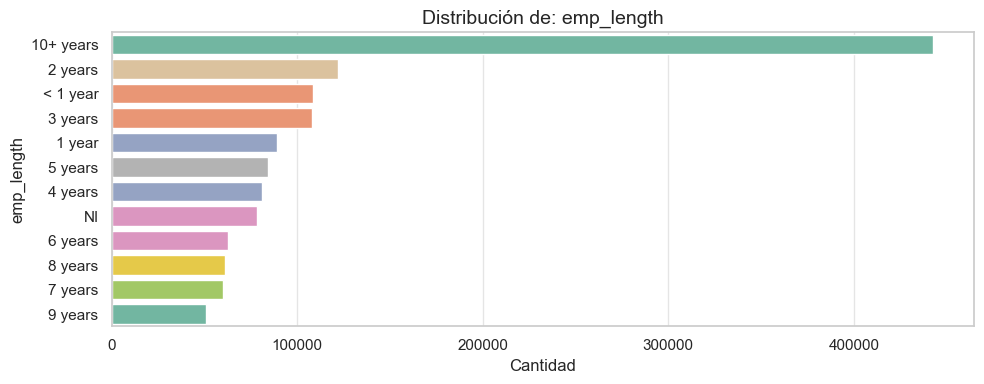

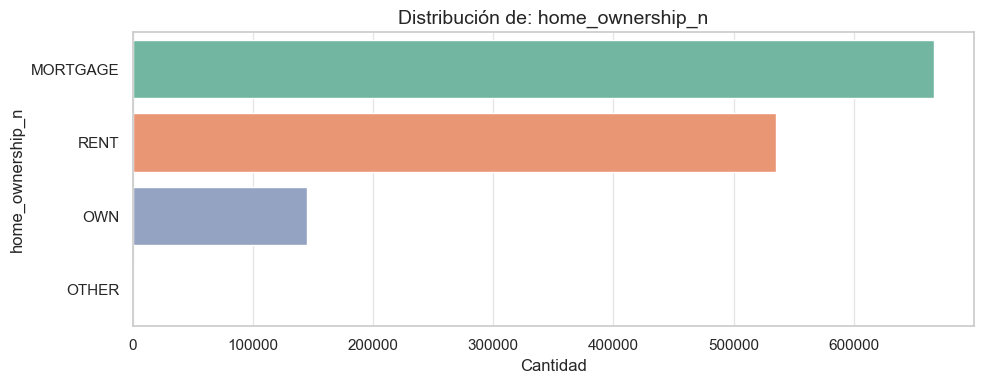

In [9]:
# Celda 8: Categóricas - Cardinalidad
# Excluimos las variables de texto libre
features_cat = [col for col in cat_cols if col not in ['title', 'desc']]

cardinality = pd.DataFrame({
    'Variable': features_cat,
    'Valores Únicos': [df[col].nunique() for col in features_cat]
}).sort_values(by='Valores Únicos', ascending=False)

display(cardinality)

# Graficamos la frecuencia de las variables con baja cardinalidad (ej. purpose o home_ownership_n)
baja_cardinalidad = cardinality[cardinality['Valores Únicos'] <= 20]['Variable'].tolist()

for col in baja_cardinalidad:
    plt.figure(figsize=(10, 4))
    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().index,
        hue=col,
        palette='Set2',
        legend=False
    )
    plt.title(f'Distribución de: {col}', fontsize=14)
    plt.xlabel('Cantidad')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

#### Análisis Bivariado
- Vamos a cruzar las varibales categóricas de baja cardinalidad numéricas más limpias contra nuestrra variblae objetivo para ver si los "Malos pagadores" tienen sueldos más bajos, más deudas, etc. Esto nos dará una idea de qué variables podrían ser más predictivas para nuestro modelo.

C:\Users\Equipo\AppData\Local\Temp\ipykernel_5256\1178182743.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Default', y=col, data=df, ax=axes[i], palette='Set2')
C:\Users\Equipo\AppData\Local\Temp\ipykernel_5256\1178182743.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Default', y=col, data=df, ax=axes[i], palette='Set2')


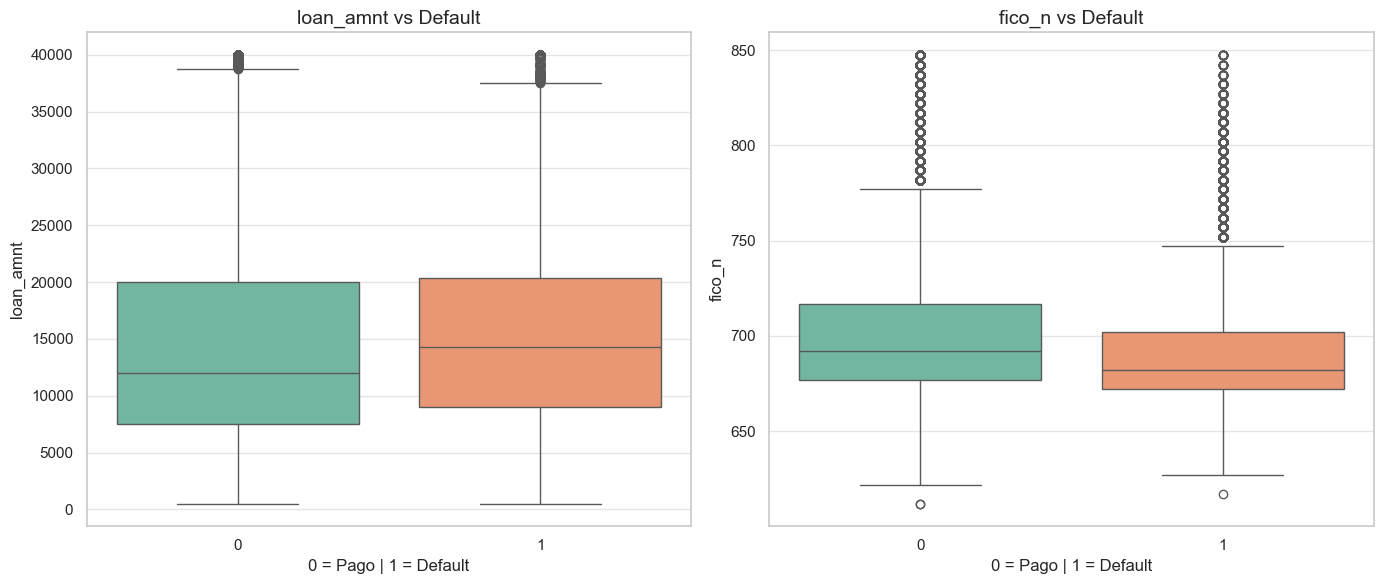

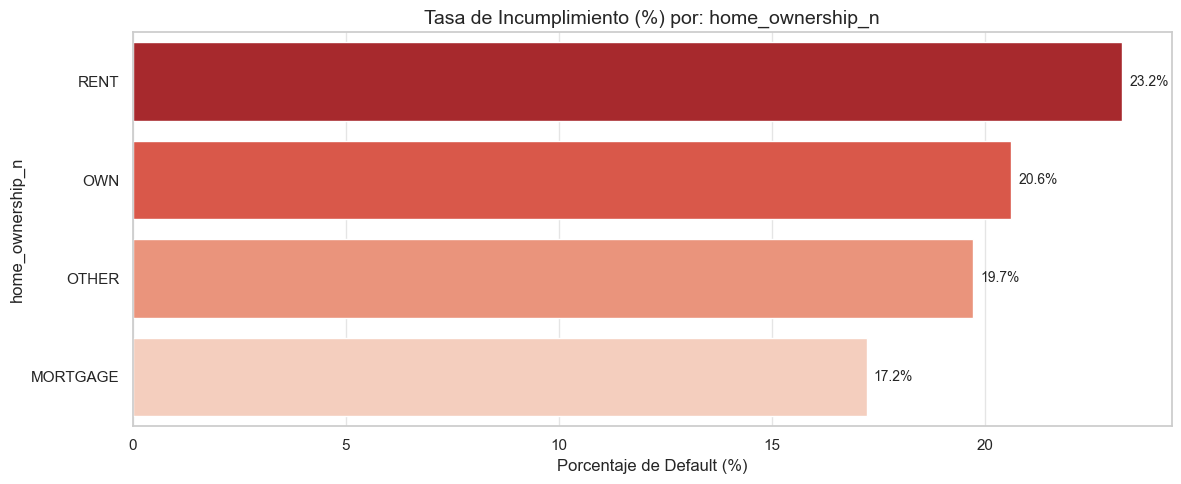

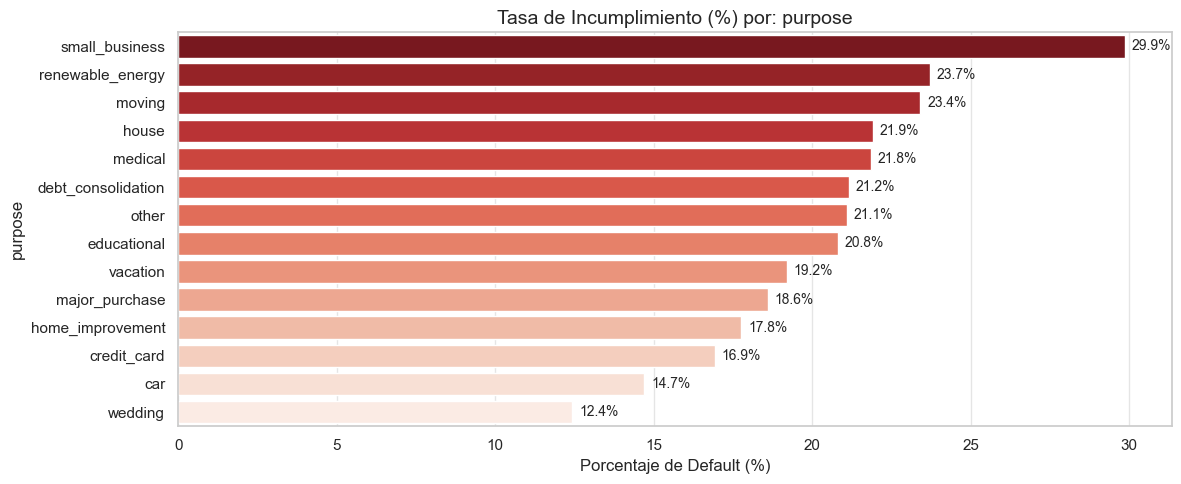

In [11]:
# Celda 9: Análisis Bivariado (Features vs. Default)

# 1. Boxplots para variables numéricas clave vs Target
# Usamos variables que no están tan distorsionadas visualmente por ahora
num_to_plot = ['loan_amnt', 'fico_n']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for i, col in enumerate(num_to_plot):
    sns.boxplot(x='Default', y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs Default', fontsize=14)
    axes[i].set_xlabel('0 = Pago | 1 = Default')
plt.tight_layout()
plt.show()

# 2. Tasa de Default por variable categórica (Ej: purpose y home_ownership_n)
cat_to_plot = ['home_ownership_n', 'purpose']

for col in cat_to_plot:
    plt.figure(figsize=(12, 5))
    # Calculamos el % de default por categoría
    target_mean = df.groupby(col)['Default'].mean().sort_values(ascending=False) * 100

    ax = sns.barplot(x=target_mean.values, y=target_mean.index, hue=target_mean.index, palette='Reds_r', legend=False)
    plt.title(f'Tasa de Incumplimiento (%) por: {col}', fontsize=14)
    plt.xlabel('Porcentaje de Default (%)')
    plt.ylabel(col)

    # Añadimos los porcentajes en las barras
    for p in ax.patches:
        width = p.get_width()
        if width > 0: # Evitar anotar barras vacías si las hay
            ax.annotate(f'{width:.1f}%',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', fontsize=10,
                        xytext=(5, 0), textcoords='offset points')
    plt.tight_layout()
    plt.show()